# Importar librerías y configurar rutas

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from packages import montecarlo as mc

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import time
import copy

from scipy.stats import norm

In [98]:
from packages.bbva_graficos import (
    BBVA,
    configurar_graficos,
    formato_es,
    guardar_mpl,
    imprimir,
)

configurar_graficos()

WindowsPath('Graficos')

In [38]:
# Número de trayectorias de Monte Carlo
NUM_SIMS = 100_000

# Semilla para que la división de datos sea reproducible
SEMILLA = 42

# Porcentajes para entrenamiento, validación y test
PROP_TRAIN = 0.70
PROP_VAL = 0.15

# Solo 3 entradas: una por activo
CANALES = [
    "ret_log_CAT",
    "ret_log_MRK",
    "ret_log_MSFT",
]

# Encontrar la raíz del proyecto al ejecutar desde un notebook
directorio_actual = Path.cwd()

RAIZ = next(
    (
        ruta
        for ruta in [directorio_actual, *directorio_actual.parents]
        if (ruta / "packages" / "montecarlo.py").exists()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError(
        "No encuentro la raíz del proyecto. "
        "Abre el notebook dentro del repositorio."
    )

RUTA_MC = RAIZ / "Datos" / "Transformados" / "montecarlo_condicionado.npz"
RUTA_PARAMETROS = RAIZ / "outputs" / "parametros_montecarlo.json"
RUTA_SALIDA = RAIZ / "Datos" / "Transformados" / "rnn_dataset.npz"

print("Raíz del proyecto:", RAIZ)
print("Archivo Monte Carlo:", RUTA_MC)
print("Archivo de salida:", RUTA_SALIDA)

Raíz del proyecto: c:\BDATA 3\26_27_R09_Azul_Claro
Archivo Monte Carlo: c:\BDATA 3\26_27_R09_Azul_Claro\Datos\Transformados\montecarlo_condicionado.npz
Archivo de salida: c:\BDATA 3\26_27_R09_Azul_Claro\Datos\Transformados\rnn_dataset.npz


# Comprobar los parámetros de Monte Carlo

In [39]:
if not RUTA_PARAMETROS.exists():
    raise FileNotFoundError(
        f"No encuentro el archivo: {RUTA_PARAMETROS}"
    )

parametros = json.loads(
    RUTA_PARAMETROS.read_text(encoding="utf-8")
)

if not np.array_equal(
    np.ravel(parametros["sigma"]),
    mc.SIGMA
):
    raise ValueError(
        "La sigma del módulo Monte Carlo no coincide con la del JSON."
    )

if not np.array_equal(
    np.array(parametros["rho"]),
    mc.RHO
):
    raise ValueError(
        "La rho del módulo Monte Carlo no coincide con la del JSON."
    )

print("Sigma y rho coinciden con los parámetros guardados.")

Sigma y rho coinciden con los parámetros guardados.


# Cargar los datos simulados

In [40]:
if not RUTA_MC.exists():
    raise FileNotFoundError(
        f"No encuentro {RUTA_MC}. "
        "Ejecuta primero el notebook de Monte Carlo."
    )

datos = np.load(RUTA_MC, allow_pickle=False)

print("Contenido del archivo Monte Carlo:\n")

for clave in datos.files:
    print(
        f"{clave:20s} "
        f"forma = {str(datos[clave].shape):18s} "
        f"tipo = {datos[clave].dtype}"
    )

# Extraer las variables
X = datos["X"]
retornos = datos["retornos_log"]
payoff = datos["payoff"]
Y = datos["Y"]
tiempos = datos["tiempos"]

Contenido del archivo Monte Carlo:

X                    forma = (100000, 20, 3)    tipo = float64
retornos_log         forma = (100000, 20, 3)    tipo = float64
retornos_simples     forma = (100000, 20, 3)    tipo = float64
payoff               forma = (100000,)          tipo = float64
Y                    forma = (100000, 20)       tipo = float64
id_simulacion        forma = (100000,)          tipo = int64
tiempos              forma = (20,)              tipo = float64
activos              forma = (3,)               tipo = <U4
S0                   forma = (3,)               tipo = float64
sigma                forma = (3,)               tipo = float64
rho                  forma = (3, 3)             tipo = float64
r                    forma = ()                 tipo = float64
TTM                  forma = ()                 tipo = int64
dt                   forma = ()                 tipo = float64
strike               forma = ()                 tipo = int64
semilla              forma = 

In [41]:
# Comprobar que los primeros 5 instantes son iguales
if not np.allclose(
    X[:, :5, :],
    X[0:1, :5, :]
):
    raise ValueError(
        "Las primeras 5 observaciones no son iguales."
    )
else:
    print("Las primeras 5 observaciones son iguales.")

Las primeras 5 observaciones son iguales.


In [42]:
if not np.allclose(
    retornos[:, :5, :],
    retornos[0:1, :5, :]
):
    raise ValueError(
        "Las primeras 5 rentabilidades no son iguales."
    )
else:
    print("Las primeras 5 rentabilidades son iguales.")

Las primeras 5 rentabilidades son iguales.


# Comprobar que los datos son correctos

In [43]:
# Comprobar que X no contiene valores inválidos
if not np.isfinite(X).all():
    raise ValueError("X contiene valores inválidos.")

# Comprobar que los retornos no contienen valores inválidos
if not np.isfinite(retornos).all():
    raise ValueError("Hay retornos inválidos.")

# Comprobar que los payoffs no contienen valores inválidos
if not np.isfinite(payoff).all():
    raise ValueError("Hay payoffs inválidos.")

# Comprobar que no hay payoffs negativos
if not (payoff >= 0).all():
    raise ValueError("Hay payoffs negativos.")

print("Todas las comprobaciones se han superado correctamente.")

Todas las comprobaciones se han superado correctamente.


In [44]:
# Comprobar la forma de X
if X.shape != (NUM_SIMS, mc.NUM_PASOS, 3):
    raise ValueError(f"Forma inesperada de X: {X.shape}")

# Comprobar sigma
if not np.array_equal(datos["sigma"], mc.SIGMA):
    raise ValueError("La sigma del archivo no coincide con la del módulo Monte Carlo.")

# Comprobar rho
if not np.array_equal(datos["rho"], mc.RHO):
    raise ValueError("La rho del archivo no coincide con la del módulo Monte Carlo.")

# Comprobar los retornos
if not np.array_equal(retornos, mc.retornos_log(X)):
    raise ValueError("Los retornos no coinciden con los calculados por el módulo Monte Carlo.")

# Comprobar los tiempos
if not np.array_equal(tiempos, mc.TIEMPOS):
    raise ValueError("Los tiempos no coinciden con los del módulo Monte Carlo.")

# Comprobar la forma del payoff
if payoff.shape != (NUM_SIMS,):
    raise ValueError(f"Forma inesperada del payoff: {payoff.shape}")

# Comprobar las dimensiones de Y
if Y.ndim != 2:
    raise ValueError("Y debe tener dos dimensiones.")

if Y.shape[0] != NUM_SIMS:
    raise ValueError("Y debe tener una fila por trayectoria.")

if Y.shape[1] == 0:
    raise ValueError("Y no contiene pasos temporales.")

# Comprobar si el último valor de Y coincide con el payoff
if not np.array_equal(Y[:, -1], payoff):
    raise ValueError("El último valor de Y no coincide con el payoff.")

# Prima inicial de referencia: media del payoff descontada hasta t=0
prima_t0 = payoff.mean() * np.exp(-mc.R * mc.TTM)

# Porcentaje de trayectorias con payoff positivo
pct_itm = 100 * (payoff > 0).mean()

print(f"Número de trayectorias: {len(payoff):,}")
print(f"Payoff medio al vencimiento: {payoff.mean():.6f}")
print(f"Prima inicial estimada: {prima_t0:.6f}")
print(f"Trayectorias con payoff positivo: {pct_itm:.3f}%")

Número de trayectorias: 100,000
Payoff medio al vencimiento: 0.162241
Prima inicial estimada: 0.154328
Trayectorias con payoff positivo: 38.908%


# Crear las entradas y el objetivo de la red

In [45]:
# ENTRADAS:
# 100.000 trayectorias, 20 pasos, 3 activos
entradas = retornos.astype(np.float32)

# OBJETIVO:
# Un único payoff al vencimiento por trayectoria
objetivo_payoff = payoff.astype(np.float32)

print("Forma de las entradas:", entradas.shape)
print("Forma del objetivo:", objetivo_payoff.shape)

Forma de las entradas: (100000, 20, 3)
Forma del objetivo: (100000,)


# Separar entrenamiento, validación y test

In [46]:
# Separar entrenamiento, validación y test
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# Número real de trayectorias disponibles
n_total = len(entradas)

# Mezclar aleatoriamente los índices
indices = rng.permutation(n_total)

# Calcular cuántas trayectorias van a cada conjunto
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)

# Repartir los índices
idx_train = indices[:n_train]
idx_val = indices[n_train:n_train + n_val]
idx_test = indices[n_train + n_val:]

# Comprobar las cantidades
if len(idx_train) != n_train:
    raise ValueError("El número de trayectorias de entrenamiento no es correcto.")

if len(idx_val) != n_val:
    raise ValueError("El número de trayectorias de validación no es correcto.")

if len(idx_test) != n_total - n_train - n_val:
    raise ValueError("El número de trayectorias de test no es correcto.")

# Comprobar que ningún índice se repite
todos_indices = np.concatenate(
    [idx_train, idx_val, idx_test]
)

if len(np.unique(todos_indices)) != n_total:
    raise ValueError("Hay índices repetidos o faltan índices en los conjuntos.")

print(f"Entrenamiento: {len(idx_train):,}")
print(f"Validación:    {len(idx_val):,}")
print(f"Test:          {len(idx_test):,}")

Entrenamiento: 70,000
Validación:    15,000
Test:          15,000


# Guardar el conjunto de datos preparado

In [47]:
RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)

np.savez(
    RUTA_SALIDA,

    # Entradas y objetivo principal de la red
    entradas=entradas,
    objetivo_payoff=objetivo_payoff,

    # Datos originales conservados
    X=X,
    retornos_log=retornos,
    payoff=payoff,
    Y=Y,
    tiempos=tiempos,

    # Nombres de los canales de entrada
    canales=np.array(CANALES),

    # División de los datos
    idx_train=idx_train,
    idx_val=idx_val,
    idx_test=idx_test,

    # Conservamos el escalado original de Y por compatibilidad
    media_Y=Y[idx_train].mean(),
    desv_Y=Y[idx_train].std(),

    semilla=SEMILLA,
)

# Resumen y comprobaciones finales

In [48]:
print("RESUMEN DEL CONJUNTO DE DATOS")
print("-" * 40)

print("Entradas:", entradas.shape)
print("Objetivo payoff:", objetivo_payoff.shape)

for nombre, indices in [
    ("Entrenamiento", idx_train),
    ("Validación", idx_val),
    ("Test", idx_test),
]:
    porcentaje_positivos = 100 * (
        objetivo_payoff[indices] > 0
    ).mean()

    print(
        f"{nombre}: {len(indices):,} trayectorias; "
        f"{porcentaje_positivos:.2f}% con payoff positivo"
    )

print("\nPrimeros 5 payoffs:")
print(objetivo_payoff[:5])

print("\n¿Hay valores no finitos en las entradas?",
      not np.isfinite(entradas).all())

print("¿Hay valores no finitos en el objetivo?",
      not np.isfinite(objetivo_payoff).all())

RESUMEN DEL CONJUNTO DE DATOS
----------------------------------------
Entradas: (100000, 20, 3)
Objetivo payoff: (100000,)
Entrenamiento: 70,000 trayectorias; 38.73% con payoff positivo
Validación: 15,000 trayectorias; 39.50% con payoff positivo
Test: 15,000 trayectorias; 39.13% con payoff positivo

Primeros 5 payoffs:
[0.03805653 0.         0.         0.         0.        ]

¿Hay valores no finitos en las entradas? False
¿Hay valores no finitos en el objetivo? False


# Gráfico de la distribución del payoff

Guardado: Graficos\distribucion_payoff_positivo.png


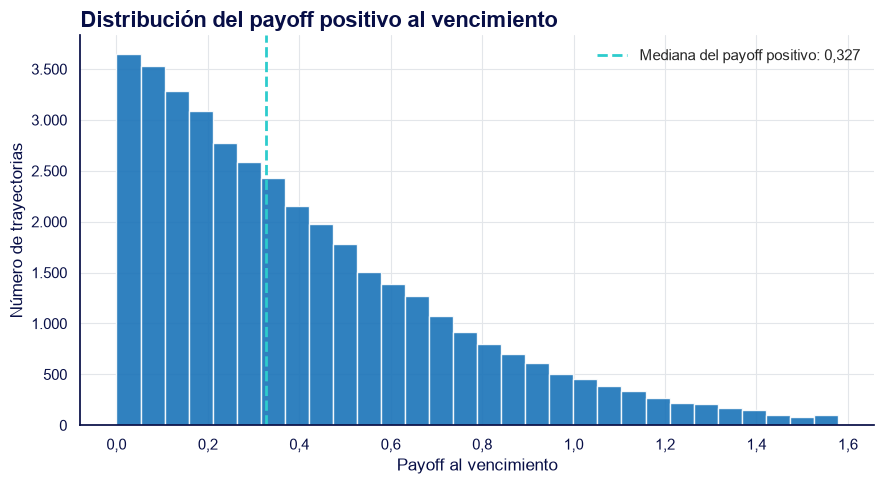

In [ ]:
positivos = objetivo_payoff[objetivo_payoff > 0]

mediana = np.median(positivos)
p99 = np.percentile(positivos, 99)

fig, ax = plt.subplots(figsize=(9, 5))

# Histograma
ax.hist(
    positivos,
    bins=30,
    range=(0, p99),
    color=BBVA["medio"],
    edgecolor=BBVA["blanco"],
    alpha=0.9,
)

# Línea de la mediana
ax.axvline(
    mediana,
    color=BBVA["agua"],
    linewidth=2,
    linestyle="--",
    label=f"Mediana del payoff positivo: {mediana:.3f}",
)

# Títulos y etiquetas
ax.set_title("Distribución del payoff positivo al vencimiento")
ax.set_xlabel("Payoff al vencimiento")
ax.set_ylabel("Número de trayectorias")
ax.legend()

# Formato y guardado BBVA
formato_es(fig)

fig.tight_layout()

guardar_mpl(fig, "distribucion_payoff_positivo")

plt.show()

# Configurar el entrenamiento

In [50]:
SEMILLA = 42

torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

DISPOSITIVO = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH = 512
LR = 1e-3
MAX_EPOCAS = 150
PACIENCIA = 10
MIN_DELTA = 1e-6

print("Dispositivo:", DISPOSITIVO)

Dispositivo: cpu


# Cargar las entradas y el payoff final

In [51]:
RUTA_DATASET = RAIZ / "Datos" / "Transformados" / "rnn_dataset.npz"

datos_np = np.load(RUTA_DATASET, allow_pickle=False)

print("Variables guardadas:")
print(datos_np.files)

Variables guardadas:
['entradas', 'objetivo_payoff', 'X', 'retornos_log', 'payoff', 'Y', 'tiempos', 'canales', 'idx_train', 'idx_val', 'idx_test', 'media_Y', 'desv_Y', 'semilla']


In [52]:
# Entradas: 100.000 trayectorias, 20 pasos y 3 activos
X = datos_np["entradas"].astype(np.float32)

# Payoff final: un único valor por trayectoria
if "objetivo_payoff" in datos_np.files:
    payoff = datos_np["objetivo_payoff"].astype(np.float32)
else:
    payoff = datos_np["payoff"].astype(np.float32)

print("Forma de X:", X.shape)
print("Forma del payoff:", payoff.shape)

Forma de X: (100000, 20, 3)
Forma del payoff: (100000,)


In [53]:
# Comprobar que X tiene tres dimensiones
if X.ndim != 3:
    raise ValueError("X debe tener tres dimensiones.")

# Comprobar que cada trayectoria tiene 20 pasos y 3 activos
if X.shape[1:] != (20, 3):
    raise ValueError(f"Forma inesperada de X: {X.shape}")

# Comprobar que hay un payoff por cada trayectoria
if payoff.shape != (len(X),):
    raise ValueError(f"Forma inesperada de payoff: {payoff.shape}")

# Comprobar que X no contiene valores inválidos
if not np.isfinite(X).all():
    raise ValueError("X contiene valores inválidos.")

# Comprobar que payoff no contiene valores inválidos
if not np.isfinite(payoff).all():
    raise ValueError("Payoff contiene valores inválidos.")

# Comprobar que no hay payoffs negativos
if not (payoff >= 0).all():
    raise ValueError("Hay payoffs negativos.")

print("Comprobaciones superadas.")

Comprobaciones superadas.


# Dividir los datos en entrenamiento, validación y test

In [54]:
idx_train = datos_np["idx_train"]
idx_val = datos_np["idx_val"]
idx_test = datos_np["idx_test"]

X_train = X[idx_train]
X_val = X[idx_val]
X_test = X[idx_test]

y_train = payoff[idx_train]
y_val = payoff[idx_val]
y_test = payoff[idx_test]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Entrenamiento: (70000, 20, 3) (70000,)
Validación: (15000, 20, 3) (15000,)
Test: (15000, 20, 3) (15000,)


# Escalar los datos

In [55]:
# Escalado de las entradas, usando solo entrenamiento
media_X = X_train.mean(axis=(0, 1), keepdims=True)
desv_X = X_train.std(axis=(0, 1), keepdims=True)

desv_X = np.where(desv_X == 0, 1.0, desv_X)

X_train_s = (X_train - media_X) / desv_X
X_val_s = (X_val - media_X) / desv_X
X_test_s = (X_test - media_X) / desv_X

# Escalado del payoff final
media_y = float(y_train.mean())
desv_y = float(y_train.std())

if desv_y == 0:
    desv_y = 1.0

y_train_s = (y_train - media_y) / desv_y
y_val_s = (y_val - media_y) / desv_y
y_test_s = (y_test - media_y) / desv_y

print("Media del payoff:", media_y)
print("Desviación típica del payoff:", desv_y)

Media del payoff: 0.16180837154388428
Desviación típica del payoff: 0.3004840016365051


# Crear los conjuntos para PyTorch

In [56]:
datos_train = TensorDataset(
    torch.tensor(X_train_s, dtype=torch.float32),
    torch.tensor(y_train_s, dtype=torch.float32)
)

datos_val = TensorDataset(
    torch.tensor(X_val_s, dtype=torch.float32),
    torch.tensor(y_val_s, dtype=torch.float32)
)

datos_test = TensorDataset(
    torch.tensor(X_test_s, dtype=torch.float32),
    torch.tensor(y_test_s, dtype=torch.float32)
)

loader_train = DataLoader(
    datos_train,
    batch_size=BATCH,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEMILLA)
)

loader_val = DataLoader(
    datos_val,
    batch_size=4096,
    shuffle=False
)

print("Conjuntos preparados.")

Conjuntos preparados.


# Definir la red recurrente

In [ ]:
class RedPayoffFinal(nn.Module):

    def __init__(self, tipo, n_entrada=3, n_oculta=64, num_capas=1):
        super().__init__()

        capa = {
            "rnn": nn.RNN,
            "lstm": nn.LSTM,
            "gru": nn.GRU
        }[tipo]

        self.recurrente = capa(
            input_size=n_entrada,
            hidden_size=n_oculta,
            num_layers=num_capas,
            batch_first=True
        )

        self.lineal = nn.Linear(n_oculta, 1)

    def forward(self, x):

        secuencia, _ = self.recurrente(x)

        # Solo usamos la representación del último paso disponible
        ultimo_paso = secuencia[:, -1, :]

        # Un payoff por trayectoria
        salida = self.lineal(ultimo_paso).squeeze(-1)

        return salida


# Crear la función de entrenamiento

In [58]:
def entrenar_payoff(modelo, lr=LR):

    modelo = modelo.to(DISPOSITIVO)

    optimizador = torch.optim.Adam(
        modelo.parameters(),
        lr=lr
)

    perdida = nn.MSELoss()

    historial = {
        "train": [],
        "val": []
    }

    mejor_val = float("inf")
    mejor_estado = None
    mejor_epoca = 0
    sin_mejora = 0

    inicio = time.perf_counter()

    for epoca in range(1, MAX_EPOCAS + 1):

        # Entrenamiento
        modelo.train()
        suma_train = 0.0

        for xb, yb in loader_train:
            xb = xb.to(DISPOSITIVO)
            yb = yb.to(DISPOSITIVO)

            optimizador.zero_grad()

            pred = modelo(xb)
            loss = perdida(pred, yb)

            loss.backward()

            nn.utils.clip_grad_norm_(
                modelo.parameters(), 1.0
            )

            optimizador.step()

            suma_train += loss.item() * len(xb)

        loss_train = suma_train / len(datos_train)

        # Validación
        modelo.eval()
        suma_val = 0.0

        with torch.no_grad():
            for xb, yb in loader_val:
                xb = xb.to(DISPOSITIVO)
                yb = yb.to(DISPOSITIVO)

                pred = modelo(xb)
                loss = perdida(pred, yb)

                suma_val += loss.item() * len(xb)

        loss_val = suma_val / len(datos_val)

        historial["train"].append(loss_train)
        historial["val"].append(loss_val)

        # Guardar el mejor modelo
        if loss_val < mejor_val - MIN_DELTA:
            mejor_val = loss_val
            mejor_epoca = epoca
            mejor_estado = copy.deepcopy(modelo.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0:
            print(
                f"Época {epoca:3d} | "
                f"Train: {loss_train:.5f} | "
                f"Val: {loss_val:.5f}"
            )

        if sin_mejora >= PACIENCIA:
            print("Parada temprana.")
            break

    tiempo = time.perf_counter() - inicio

    modelo.load_state_dict(mejor_estado)

    return modelo, {
        "historial": historial,
        "mejor_epoca": mejor_epoca,
        "mejor_val": mejor_val,
        "epocas": epoca,
        "tiempo": tiempo
    }

# Entrenar las tres arquitecturas

In [ ]:
# Busqueda de hiperparametros
estructuras = {
    "RNN simple": "rnn",
    "LSTM": "lstm",
    "GRU": "gru"
}

# Valores que vamos a probar
NEURONAS = [32, 64, 128]
TASAS_APRENDIZAJE = [1e-3, 3e-4]
NUM_CAPAS = [1, 2]

# Guardar el mejor modelo y su configuración para cada arquitectura
modelos = {}
resultados_entrenamiento = {}
configuraciones = {}

# Guardar los resultados de TODAS las configuraciones probadas
todas_las_pruebas = []

# Recorrer las tres arquitecturas
for nombre, tipo in estructuras.items():

    print(f"\n{'=' * 50}")
    print(f"Buscando hiperparámetros para: {nombre}")
    print("=" * 50)

    mejor_val_arquitectura = float("inf")
    mejor_modelo_arquitectura = None
    mejor_resultado_arquitectura = None
    mejor_configuracion = None

    # Probar neuronas, tasa de aprendizaje y número de capas
    for n_oculta in NEURONAS:
        for lr in TASAS_APRENDIZAJE:
            for num_capas in NUM_CAPAS:

                print(
                    f"\nProbando {nombre}: "
                    f"neuronas={n_oculta}, "
                    f"lr={lr}, "
                    f"capas={num_capas}"
                )

                # Fijar las semillas para reproducibilidad
                torch.manual_seed(SEMILLA)
                np.random.seed(SEMILLA)

                # Crear el modelo
                modelo = RedPayoffFinal(
                    tipo=tipo,
                    n_entrada=3,
                    n_oculta=n_oculta,
                    num_capas=num_capas
                )

                # Entrenar con la tasa de aprendizaje probada
                modelo, resultado = entrenar_payoff(
                    modelo,
                    lr=lr
                )

                # Registrar los resultados de esta configuración
                todas_las_pruebas.append({
                    "Arquitectura": nombre,
                    "Neuronas ocultas": n_oculta,
                    "Tasa de aprendizaje": lr,
                    "Capas": num_capas,
                    "MSE validación": resultado["mejor_val"],
                    "Mejor época": resultado["mejor_epoca"],
                    "Tiempo (s)": resultado["tiempo"]
                })

                # Elegir la mejor configuración usando validación
                if resultado["mejor_val"] < mejor_val_arquitectura:

                    mejor_val_arquitectura = resultado["mejor_val"]
                    mejor_modelo_arquitectura = modelo
                    mejor_resultado_arquitectura = resultado

                    mejor_configuracion = {
                        "arquitectura": nombre,
                        "n_oculta": n_oculta,
                        "lr": lr,
                        "num_capas": num_capas
                    }

    # Guardar la mejor configuración de esta arquitectura
    modelos[nombre] = mejor_modelo_arquitectura
    resultados_entrenamiento[nombre] = mejor_resultado_arquitectura
    configuraciones[nombre] = mejor_configuracion

    print(f"\nMejor configuración para {nombre}:")
    print(mejor_configuracion)
    print(
        "Mejor MSE de validación:",
        mejor_val_arquitectura
    )


# TABLA 1: todas las configuraciones probadas
tabla_todas_las_pruebas = (
    pd.DataFrame(todas_las_pruebas)
    .sort_values("MSE validación")
    .reset_index(drop=True)
)

print("\nRESULTADOS DE TODAS LAS CONFIGURACIONES")
display(tabla_todas_las_pruebas)


# TABLA 2: mejor configuración de cada arquitectura
tabla_hiperparametros = pd.DataFrame([
    {
        "Arquitectura": nombre,
        "Neuronas ocultas": configuraciones[nombre]["n_oculta"],
        "Tasa de aprendizaje": configuraciones[nombre]["lr"],
        "Capas": configuraciones[nombre]["num_capas"],
        "MSE validación": resultados_entrenamiento[nombre]["mejor_val"],
        "Mejor época": resultados_entrenamiento[nombre]["mejor_epoca"],
        "Tiempo (s)": resultados_entrenamiento[nombre]["tiempo"]
    }
    for nombre in estructuras
]).sort_values("MSE validación").reset_index(drop=True)

print("\nMEJOR CONFIGURACIÓN DE CADA ARQUITECTURA")
display(tabla_hiperparametros)




Buscando hiperparámetros para: RNN simple

Probando RNN simple: neuronas=32, lr=0.001, capas=1
Época   1 | Train: 0.47433 | Val: 0.16793
Época  10 | Train: 0.02621 | Val: 0.02318
Época  20 | Train: 0.01724 | Val: 0.01237
Época  30 | Train: 0.01475 | Val: 0.01656
Época  40 | Train: 0.01351 | Val: 0.01258
Parada temprana.

Probando RNN simple: neuronas=32, lr=0.001, capas=2
Época   1 | Train: 0.25891 | Val: 0.04405
Época  10 | Train: 0.01826 | Val: 0.01716
Época  20 | Train: 0.01445 | Val: 0.02795
Época  30 | Train: 0.01107 | Val: 0.00758
Época  40 | Train: 0.00903 | Val: 0.01186
Época  50 | Train: 0.00920 | Val: 0.00511
Parada temprana.

Probando RNN simple: neuronas=32, lr=0.0003, capas=1
Época   1 | Train: 0.81571 | Val: 0.32145
Época  10 | Train: 0.02956 | Val: 0.02314
Época  20 | Train: 0.02048 | Val: 0.01627
Época  30 | Train: 0.01349 | Val: 0.01353
Parada temprana.

Probando RNN simple: neuronas=32, lr=0.0003, capas=2
Época   1 | Train: 0.51567 | Val: 0.14416
Época  10 | Train: 0

,Arquitectura,Neuronas ocultas,Tasa de aprendizaje,Capas,MSE validación,Mejor época,Tiempo (s)
0,GRU,64,0.0003,2,0.000037,134,1344.534458
1,GRU,128,0.0003,2,0.000048,75,1606.822673
2,LSTM,64,0.0003,2,0.000054,104,950.657444
3,GRU,128,0.0010,1,0.000080,62,780.594242
4,GRU,64,0.0010,2,0.000081,52,566.039956
5,LSTM,128,0.0010,2,0.000081,42,1637.238609
6,GRU,128,0.0010,2,0.000083,36,896.562860
7,LSTM,128,0.0010,1,0.000084,72,714.305685
8,GRU,128,0.0003,1,0.000093,92,884.266246
9,LSTM,64,0.0010,2,0.000095,52,497.178894



MEJOR CONFIGURACIÓN DE CADA ARQUITECTURA


,Arquitectura,Neuronas ocultas,Tasa de aprendizaje,Capas,MSE validación,Mejor época,Tiempo (s)
0,GRU,64,0.0003,2,0.000037,134,1344.534458
1,LSTM,64,0.0003,2,0.000054,104,950.657444
2,RNN simple,128,0.0010,1,0.000614,85,320.324533


Guardado: Graficos\perdida_entrenamiento_validacion.png


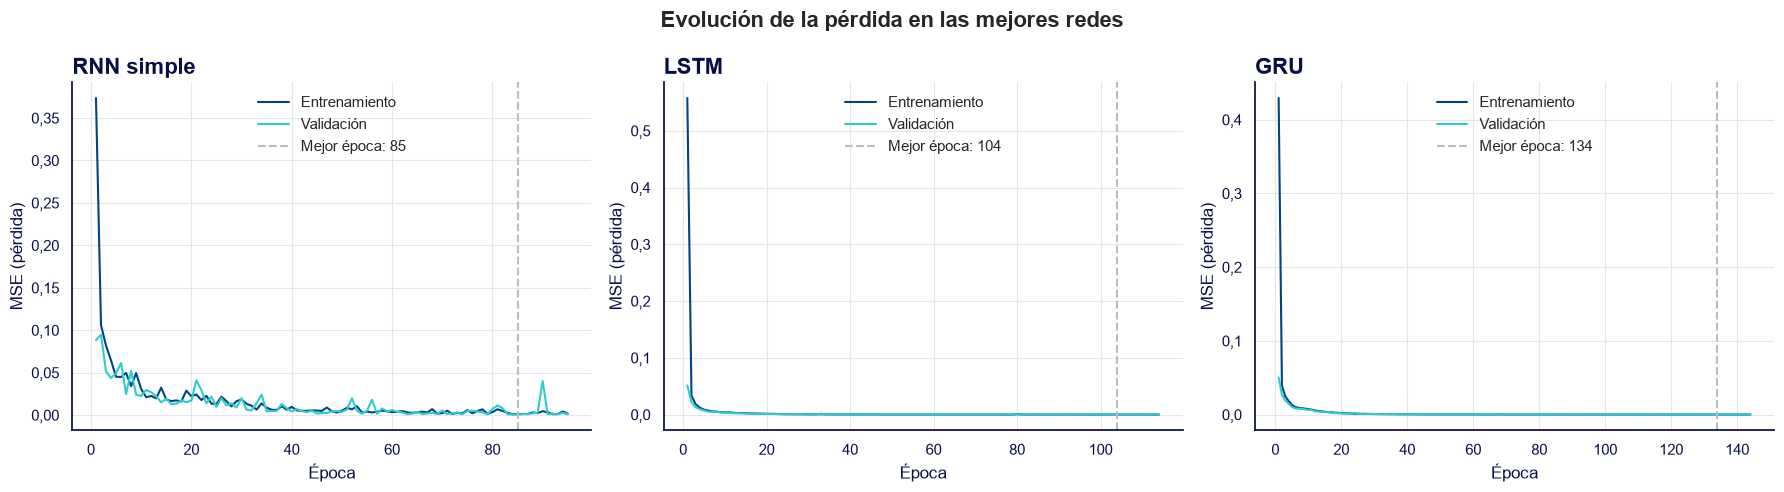

In [100]:
# GRÁFICO 1: PÉRDIDA DE ENTRENAMIENTO Y VALIDACIÓN

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nombre in zip(axes, estructuras.keys()):

    historial = resultados_entrenamiento[nombre]["historial"]

    epocas = range(1, len(historial["train"]) + 1)

    # Pérdida de entrenamiento
    ax.plot(
        epocas,
        historial["train"],
        color=BBVA["principal"],
        label="Entrenamiento"
    )

    # Pérdida de validación
    ax.plot(
        epocas,
        historial["val"],
        color=BBVA["agua"],
        label="Validación"
    )

    # Mejor época
    mejor_epoca = resultados_entrenamiento[nombre]["mejor_epoca"]

    ax.axvline(
        mejor_epoca,
        color=BBVA["gris_dato"],
        linestyle="--",
        linewidth=1.5,
        label=f"Mejor época: {mejor_epoca}"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Época")
    ax.set_ylabel("MSE (pérdida)")
    ax.legend()

fig.suptitle(
    "Evolución de la pérdida en las mejores redes",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

# Formato y guardado BBVA
formato_es(fig)

guardar_mpl(fig, "perdida_entrenamiento_validacion")

plt.show()

# Comparar las predicciones en test

In [115]:
def predecir_payoff(modelo, X_escalado):

    modelo.eval()
    predicciones = []

    with torch.no_grad():
        for inicio in range(0, len(X_escalado), 8192):

            xb = torch.tensor(
                X_escalado[inicio:inicio + 8192],
                dtype=torch.float32,
                device=DISPOSITIVO
            )

            pred = modelo(xb).cpu().numpy()
            predicciones.append(pred)

    pred_escalado = np.concatenate(predicciones)

    # Deshacer el escalado y asegurar payoff >= 0
    pred_real = pred_escalado * desv_y + media_y

    return np.maximum(pred_real, 0)


# Comparar las predicciones de RNN, LSTM y GRU en test
predicciones_test = {}
filas = []

for nombre, modelo in modelos.items():

    pred = predecir_payoff(modelo, X_test_s)
    predicciones_test[nombre] = pred

    filas.append({
        "Modelo": nombre,
        "Neuronas ocultas": configuraciones[nombre]["n_oculta"],
        "Tasa de aprendizaje": configuraciones[nombre]["lr"],
        "Número de capas": configuraciones[nombre]["num_capas"],
        "MSE validación": resultados_entrenamiento[nombre]["mejor_val"],
        "MAE test": mean_absolute_error(y_test, pred),
        "RMSE test": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 test": r2_score(y_test, pred),
        "Mejor época": resultados_entrenamiento[nombre]["mejor_epoca"],
        "Tiempo (s)": resultados_entrenamiento[nombre]["tiempo"]
    })


# Mostrar los resultados ordenados por RMSE de test
tabla_resultados = (
    pd.DataFrame(filas)
    .sort_values("RMSE test")
    .reset_index(drop=True)
)

display(tabla_resultados)


,Modelo,Neuronas ocultas,Tasa de aprendizaje,Número de capas,MSE validación,MAE test,RMSE test,R2 test,Mejor época,Tiempo (s)
0,GRU,64,0.0003,2,0.000037,0.000998,0.001854,0.999963,134,1344.534458
1,LSTM,64,0.0003,2,0.000054,0.001034,0.002262,0.999945,104,950.657444
2,RNN simple,128,0.0010,1,0.000614,0.004393,0.008392,0.999248,85,320.324533


Guardado: Graficos\payoff_real_vs_predicho_test.png


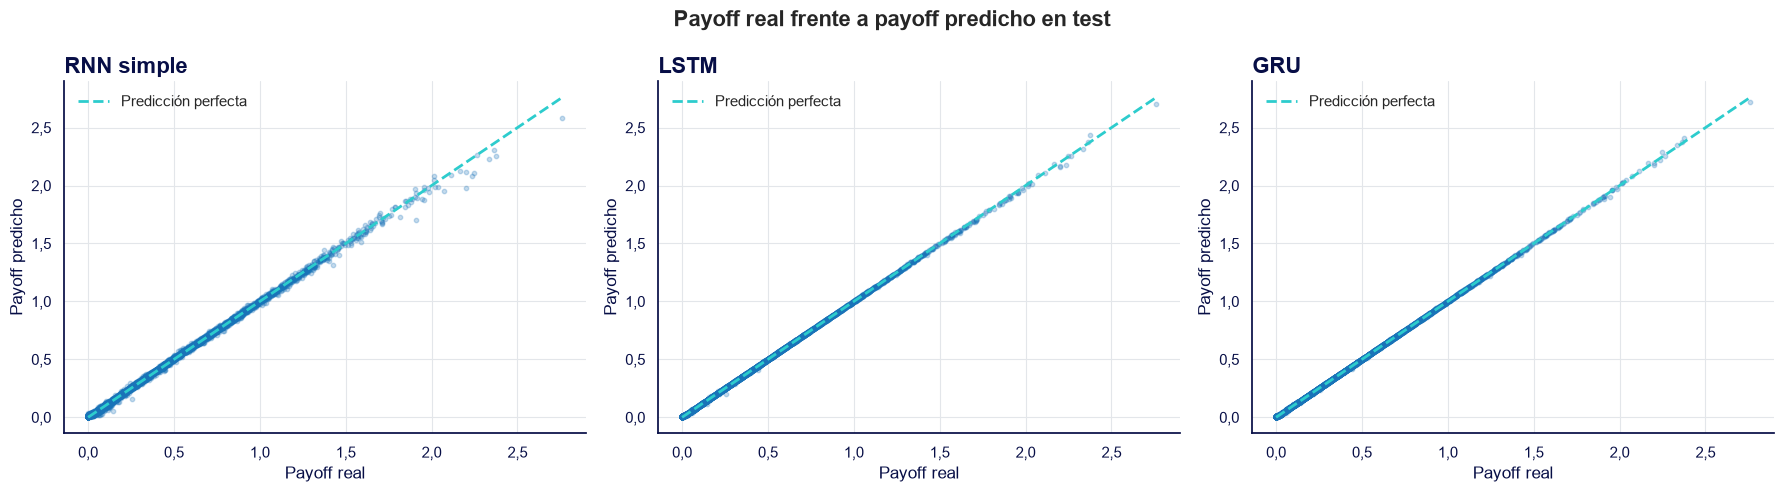

In [120]:
# GRÁFICO 2: PAYOFF REAL FRENTE A PAYOFF PREDICHO EN TEST

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nombre in zip(axes, estructuras.keys()):

    pred = predicciones_test[nombre]

    # Puntos: payoff real frente a predicho
    ax.scatter(
        y_test,
        pred,
        color=BBVA["medio"],
        alpha=0.25,
        s=10
    )

    # Línea de predicción perfecta
    minimo = min(y_test.min(), pred.min())
    maximo = max(y_test.max(), pred.max())

    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        color=BBVA["agua"],
        linestyle="--",
        linewidth=2,
        label="Predicción perfecta"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Payoff real")
    ax.set_ylabel("Payoff predicho")
    ax.legend()

fig.suptitle(
    "Payoff real frente a payoff predicho en test",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

# Formato y guardado BBVA
formato_es(fig)

guardar_mpl(fig, "payoff_real_vs_predicho_test")

plt.show()

Guardado: Graficos\analisis_residuos_test.png


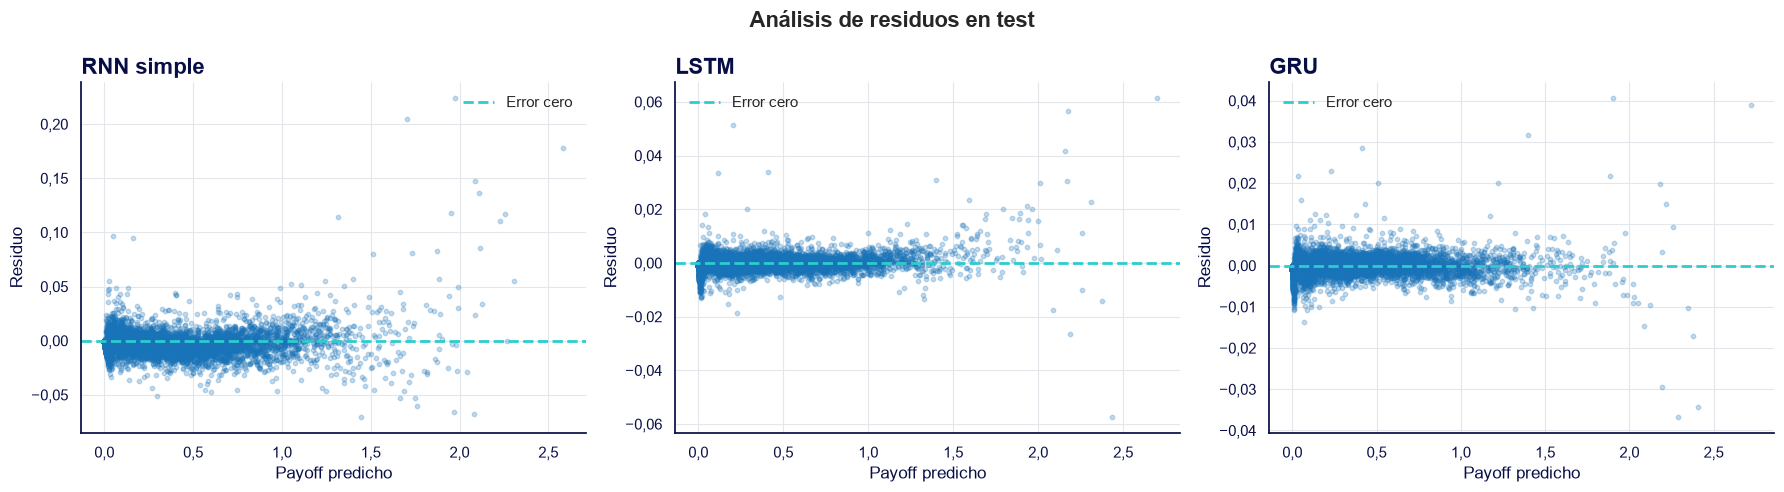

In [ ]:
# GRÁFICO 3: RESIDUOS FRENTE A PAYOFF PREDICHO

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nombre in zip(axes, estructuras.keys()):

    pred = predicciones_test[nombre]
    residuos = y_test - pred

    # Puntos: predicciones frente a residuos
    ax.scatter(
        pred,
        residuos,
        color=BBVA["medio"],
        alpha=0.25,
        s=10
    )

    # Línea de error cero
    ax.axhline(
        0,
        color=BBVA["agua"],
        linestyle="--",
        linewidth=2,
        label="Error cero"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Payoff predicho")
    ax.set_ylabel("Residuo")
    ax.legend()

fig.suptitle(
    "Análisis de residuos en test",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

# Formato y guardado BBVA
formato_es(fig)

guardar_mpl(fig, "analisis_residuos_test")

plt.show()

Guardado: Graficos\distribucion_errores_test.png


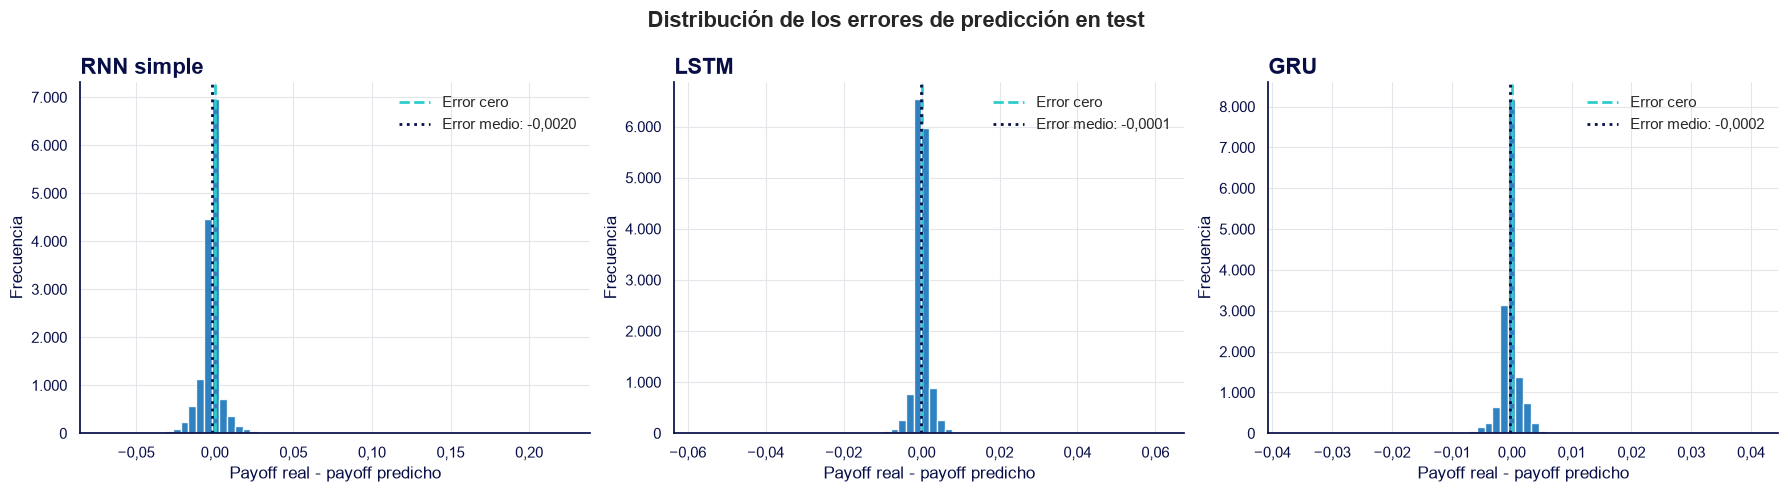

In [122]:
# GRÁFICO 4: DISTRIBUCIÓN DE LOS ERRORES

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nombre in zip(axes, estructuras.keys()):

    pred = predicciones_test[nombre]
    residuos = y_test - pred

    # Histograma de los residuos
    ax.hist(
        residuos,
        bins=60,
        color=BBVA["medio"],
        edgecolor=BBVA["blanco"],
        alpha=0.9
    )

    # Línea de error cero
    ax.axvline(
        0,
        color=BBVA["agua"],
        linestyle="--",
        linewidth=2,
        label="Error cero"
    )

    # Línea del error medio
    ax.axvline(
        residuos.mean(),
        color=BBVA["marino"],
        linestyle=":",
        linewidth=2,
        label=f"Error medio: {residuos.mean():.4f}"
    )

    ax.set_title(nombre)
    ax.set_xlabel("Payoff real - payoff predicho")
    ax.set_ylabel("Frecuencia")
    ax.legend()

fig.suptitle(
    "Distribución de los errores de predicción en test",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

# Formato y guardado BBVA
formato_es(fig)

guardar_mpl(fig, "distribucion_errores_test")

plt.show()

Guardado: Graficos\comparacion_modelos_rmse_test.png


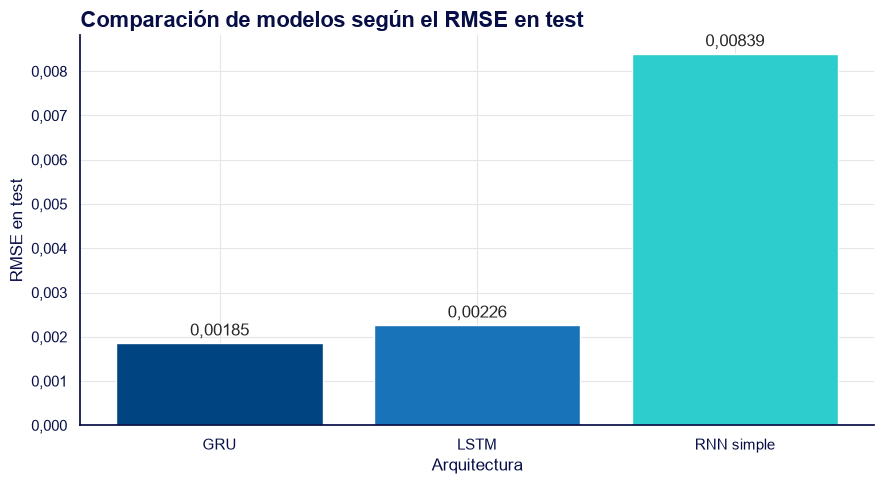

In [116]:
# GRÁFICO 5: COMPARACIÓN ENTRE RNN, LSTM Y GRU

tabla_grafico = tabla_resultados.sort_values("RMSE test")

fig, ax = plt.subplots(figsize=(9, 5))

# Gráfico de barras
barras = ax.bar(
    tabla_grafico["Modelo"],
    tabla_grafico["RMSE test"],
    color=[
        BBVA["principal"],
        BBVA["medio"],
        BBVA["agua"]
    ],
    edgecolor=BBVA["blanco"]
)

# Mostrar el valor encima de cada barra
ax.bar_label(
    barras,
    fmt="%.5f",
    padding=3
)

# Títulos y etiquetas
ax.set_title("Comparación de modelos según el RMSE en test")
ax.set_xlabel("Arquitectura")
ax.set_ylabel("RMSE en test")

# Formato y guardado BBVA
formato_es(fig)

fig.tight_layout()

guardar_mpl(fig, "comparacion_modelos_rmse_test")

plt.show()

In [109]:
mejor_nombre = min(
    resultados_entrenamiento,
    key=lambda nombre: resultados_entrenamiento[nombre]["mejor_val"]
)

mejor_modelo = modelos[mejor_nombre]

print("Modelo elegido por validación:", mejor_nombre)

Modelo elegido por validación: GRU


# Guardar el modelo elegido

In [110]:
# Guardar el modelo elegido y sus hiperparámetros

CARPETA_MODELOS = RAIZ / "modelos"
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

config_final = configuraciones[mejor_nombre]

ruta_modelo = CARPETA_MODELOS / "red_payoff_final.pt"

torch.save(
    {
        # Arquitectura seleccionada
        "tipo": estructuras[mejor_nombre],

        # Estructura de la red
        "n_entrada": 3,
        "n_oculta": config_final["n_oculta"],
        "num_capas": config_final["num_capas"],

        # Hiperparámetros
        "lr": config_final["lr"],

        # Pesos aprendidos durante el entrenamiento
        "estado": mejor_modelo.state_dict(),

        # Parámetros de escalado de las entradas
        "media_X": media_X,
        "desv_X": desv_X,

        # Parámetros de escalado del objetivo
        "media_y": media_y,
        "desv_y": desv_y,

        # Nombre del modelo
        "nombre": mejor_nombre,

        # Información adicional
        "mejor_val": resultados_entrenamiento[mejor_nombre]["mejor_val"],
        "semilla": SEMILLA
    },
    ruta_modelo
)

print("Modelo elegido:", mejor_nombre)
print("Hiperparámetros:", config_final)
print("Ruta:", ruta_modelo)
print("Modelo guardado correctamente.")

Modelo elegido: GRU
Hiperparámetros: {'arquitectura': 'GRU', 'n_oculta': 64, 'lr': 0.0003, 'num_capas': 2}
Ruta: c:\BDATA 3\26_27_R09_Azul_Claro\modelos\red_payoff_final.pt
Modelo guardado correctamente.


# Experimento: utilizar solo los primeros 15 de los 20 instantes


In [ ]:
print("\n" + "=" * 65)
print("EXPERIMENTO CON 15 INSTANTES EN VEZ DE 20")
print("=" * 65)

# 1. Preparar las entradas y los objetivos
N_INSTANTES = 15

# Utilizamos los retornos logarítmicos, igual que en el modelo original
X_15 = retornos[:, :N_INSTANTES, :]

# El objetivo sigue siendo el payoff calculado con los 20 instantes
y_15 = payoff.copy()

print("Entradas originales:", retornos.shape)
print("Entradas reducidas:", X_15.shape)
print("Objetivos:", y_15.shape)

assert X_15.shape == (len(payoff), 15, 3)
assert y_15.shape == payoff.shape

# 2. Utilizar la misma división train/val/test
X_train_15 = X_15[idx_train]
X_val_15 = X_15[idx_val]
X_test_15 = X_15[idx_test]

y_train_15 = y_15[idx_train]
y_val_15 = y_15[idx_val]
y_test_15 = y_15[idx_test]

# 3. Escalar utilizando SOLO entrenamiento
media_X_15 = X_train_15.mean(axis=(0, 1), keepdims=True)
desv_X_15 = X_train_15.std(axis=(0, 1), keepdims=True)
desv_X_15 = np.where(desv_X_15 == 0, 1.0, desv_X_15)

X_train_15_s = (X_train_15 - media_X_15) / desv_X_15
X_val_15_s = (X_val_15 - media_X_15) / desv_X_15
X_test_15_s = (X_test_15 - media_X_15) / desv_X_15

media_y_15 = float(y_train_15.mean())
desv_y_15 = float(y_train_15.std())

if desv_y_15 == 0:
    desv_y_15 = 1.0

y_train_15_s = (y_train_15 - media_y_15) / desv_y_15
y_val_15_s = (y_val_15 - media_y_15) / desv_y_15

# 4. Crear los DataLoaders
datos_train_15 = TensorDataset(
    torch.tensor(X_train_15_s, dtype=torch.float32),
    torch.tensor(y_train_15_s, dtype=torch.float32)
)

datos_val_15 = TensorDataset(
    torch.tensor(X_val_15_s, dtype=torch.float32),
    torch.tensor(y_val_15_s, dtype=torch.float32)
)

loader_train_15 = DataLoader(
    datos_train_15,
    batch_size=BATCH,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEMILLA)
)

loader_val_15 = DataLoader(
    datos_val_15,
    batch_size=4096,
    shuffle=False
)

# 5. Guardar las variables originales antes del experimento
loader_train_original = loader_train
loader_val_original = loader_val
datos_train_original = datos_train
datos_val_original = datos_val

media_y_original = media_y
desv_y_original = desv_y

# 6. Entrenar la misma arquitectura ganadora con 15 instantes
config_15 = configuraciones[mejor_nombre]

try:
    # Utilizar los datos del experimento de 15 instantes
    loader_train = loader_train_15
    loader_val = loader_val_15
    datos_train = datos_train_15
    datos_val = datos_val_15

    # La función de entrenamiento y predicción utiliza estas variables
    media_y = media_y_15
    desv_y = desv_y_15

    torch.manual_seed(SEMILLA)
    np.random.seed(SEMILLA)

    modelo_15 = RedPayoffFinal(
        tipo=estructuras[mejor_nombre],
        n_entrada=3,
        n_oculta=config_15["n_oculta"],
        num_capas=config_15["num_capas"]
    )

    modelo_15, resultado_15 = entrenar_payoff(
        modelo_15,
        lr=config_15["lr"]
    )

    print("\nArquitectura utilizada:", mejor_nombre)
    print("Configuración:", config_15)
    print("Mejor época:", resultado_15["mejor_epoca"])
    print("MSE validación (escala normalizada):", resultado_15["mejor_val"])
    print(
        "Tiempo de entrenamiento:",
        f"{resultado_15['tiempo']:.2f} segundos"
    )

    # 7. Evaluar el modelo reducido en test
    inicio_pred = time.perf_counter()

    pred_15 = predecir_payoff(modelo_15, X_test_15_s)

    tiempo_pred_15 = time.perf_counter() - inicio_pred

finally:
    # Recuperar todas las variables originales
    loader_train = loader_train_original
    loader_val = loader_val_original
    datos_train = datos_train_original
    datos_val = datos_val_original

    media_y = media_y_original
    desv_y = desv_y_original


# 8. Calcular las métricas del modelo de 15 instantes
mae_15 = mean_absolute_error(y_test_15, pred_15)
rmse_15 = np.sqrt(mean_squared_error(y_test_15, pred_15))
r2_15 = r2_score(y_test_15, pred_15)

print("\nRESULTADOS DEL MODELO CON 15 INSTANTES")
print(f"MAE test:  {mae_15:.6f}")
print(f"RMSE test: {rmse_15:.6f}")
print(f"R² test:   {r2_15:.6f}")
print(f"Tiempo de predicción test: {tiempo_pred_15:.4f} segundos")

# 9. Comparar 20 instantes frente a 15
fila_original = tabla_resultados.loc[
    tabla_resultados["Modelo"] == mejor_nombre
].iloc[0]

comparacion_instantes = pd.DataFrame([
    {
        "Instantes de entrada": 20,
        "MAE test": fila_original["MAE test"],
        "RMSE test": fila_original["RMSE test"],
        "R² test": fila_original["R2 test"],
        "Tiempo entrenamiento (s)": resultados_entrenamiento[mejor_nombre]["tiempo"]
    },
    {
        "Instantes de entrada": 15,
        "MAE test": mae_15,
        "RMSE test": rmse_15,
        "R² test": r2_15,
        "Tiempo entrenamiento (s)": resultado_15["tiempo"]
    }
])

print("\nCOMPARACIÓN: 20 INSTANTES FRENTE A 15")
display(comparacion_instantes)

# 10. Calcular la reducción del tiempo de entrenamiento
tiempo_original = resultados_entrenamiento[mejor_nombre]["tiempo"]
tiempo_reducido = resultado_15["tiempo"]

if tiempo_original > 0:
    reduccion_tiempo = (
        (tiempo_original - tiempo_reducido) / tiempo_original
    ) * 100

    print(
        f"\nReducción del tiempo de entrenamiento: "
        f"{reduccion_tiempo:.2f}%"
    )


EXPERIMENTO CON 15 INSTANTES EN VEZ DE 20
Entradas originales: (100000, 20, 3)
Entradas reducidas: (100000, 15, 3)
Objetivos: (100000,)
Época   1 | Train: 0.44364 | Val: 0.14412
Época  10 | Train: 0.07787 | Val: 0.07545
Época  20 | Train: 0.07346 | Val: 0.07306
Época  30 | Train: 0.07165 | Val: 0.07093
Época  40 | Train: 0.07051 | Val: 0.07036
Época  50 | Train: 0.06948 | Val: 0.07013
Parada temprana.

Arquitectura utilizada: GRU
Configuración: {'arquitectura': 'GRU', 'n_oculta': 64, 'lr': 0.0003, 'num_capas': 2}
Mejor época: 49
MSE validación (escala normalizada): 0.06941799675623576
Tiempo de entrenamiento: 440.04 segundos

RESULTADOS DEL MODELO CON 15 INSTANTES
MAE test:  0.042125
RMSE test: 0.079215
R² test:   0.932961
Tiempo de predicción test: 0.4155 segundos

COMPARACIÓN: 20 INSTANTES FRENTE A 15


,Instantes de entrada,MAE test,RMSE test,R² test,Tiempo entrenamiento (s)
0,20,0.000998,0.001854,0.999963,1344.534458
1,15,0.042125,0.079215,0.932961,440.044087



Reducción del tiempo de entrenamiento: 67.27%


# Valoración final y comparación de primas

Importaciones y funciones

In [ ]:
N = norm.cdf

# 1. Función Black
def Black(Forward, Strike, TTM, rate, Vol, IsCall):

    if TTM > 0:

        d1 = (
            np.log(Forward / Strike)
            + (Vol * Vol / 2) * TTM
        ) / (Vol * np.sqrt(TTM))

        d2 = (
            np.log(Forward / Strike)
            - (Vol * Vol / 2) * TTM
        ) / (Vol * np.sqrt(TTM))

        if IsCall:
            return (
                Forward * N(d1) - Strike * N(d2)
            ) * np.exp(-rate * TTM)

        return (
            -Forward * N(-d1) + Strike * N(-d2)
        ) * np.exp(-rate * TTM)

    if IsCall:
        return np.maximum(Forward - Strike, 0)

    return np.maximum(-Forward + Strike, 0)

# 2. Función BasketGeomAsian
def BasketGeomAsian(
    num_asian_dates,
    value_date_index,
    risk_free_rate,
    num_assets,
    assets_vol,
    assets_correl,
    initial_maturity,
    price_history,
    IsCall
):

    init_time_array = np.linspace(
        0, initial_maturity, num_asian_dates
    )

    pending_times_array = (
        init_time_array[value_date_index + 1:]
        - init_time_array[value_date_index]
    )

    mu = (
        np.sum(risk_free_rate - 0.5 * assets_vol * assets_vol)
        * np.sum(pending_times_array)
        / (num_assets * (num_asian_dates - 1))
    )

    diag_vol = np.diag(assets_vol.reshape(-1))

    cov_matrix = diag_vol @ assets_correl @ diag_vol

    xx, yy = np.meshgrid(
        pending_times_array,
        pending_times_array,
        sparse=True
    )

    z = np.minimum(xx, yy)

    V = (
        np.sum(cov_matrix) * np.sum(z)
        / (num_assets * num_assets * (num_asian_dates - 1) ** 2)
    )

    Forward = np.power(
        np.prod(
            price_history[:, 1:value_date_index + 1]
            / price_history[:, 0].reshape(-1, 1)
        ),
        1.0 / (num_assets * (num_asian_dates - 1))
    )

    Forward *= np.power(
        np.prod(
            price_history[:, value_date_index]
            / price_history[:, 0]
        ),
        (num_asian_dates - value_date_index - 1)
        / (num_assets * (num_asian_dates - 1))
    )

    Forward *= np.exp(mu + 0.5 * V)

    remaining_maturity = (
        initial_maturity - init_time_array[value_date_index]
    )

    return Black(
        Forward,
        1.0,
        remaining_maturity,
        risk_free_rate,
        np.sqrt(V / remaining_maturity),
        IsCall
    )

Calcular la prima BBVA en el instante 0

In [86]:
# 1. Cargar los datos de Monte Carlo
datos_mc = np.load(RUTA_MC, allow_pickle=False)

# 2. Recuperar los parámetros de la simulación
S0 = datos_mc["S0"]
sigma = datos_mc["sigma"]
rho = datos_mc["rho"]

r = float(datos_mc["r"])
TTM = float(datos_mc["TTM"])

num_assets = len(S0)
num_asian_dates = int(datos_mc["num_pasos"]) + 1

# 3. Estamos valorando en el instante 0
value_date_index = 0

# En t=0 solo conocemos los precios iniciales
price_history_t0 = S0.reshape(num_assets, 1)

# 4. Calcular la prima mediante la fórmula cerrada del profesor
prima_bbva_t0 = BasketGeomAsian(
    num_asian_dates=num_asian_dates,
    value_date_index=value_date_index,
    risk_free_rate=r,
    num_assets=num_assets,
    assets_vol=sigma,
    assets_correl=rho,
    initial_maturity=TTM,
    price_history=price_history_t0,
    IsCall=True
)

# 5. Mostrar el resultado
print("=" * 50)
print("PRIMA BBVA EN EL INSTANTE 0")
print("=" * 50)
print(f"Precios iniciales: {S0}")
print(f"Prima BBVA: {float(prima_bbva_t0):.8f}")

PRIMA BBVA EN EL INSTANTE 0
Precios iniciales: [1. 1. 1.]
Prima BBVA: 0.08316396


Calcular la prima de Monte Carlo en el instante 0

In [87]:
# 1. Recuperar los payoffs reales de las 100.000 trayectorias
payoff_total = datos_mc["payoff"]

# 2. Comprobar el número de trayectorias
print("Número total de trayectorias:", len(payoff_total))

# 3. Factor de descuento desde el vencimiento hasta t=0
factor_descuento = np.exp(-r * TTM)

# 4. Prima Monte Carlo con las 100.000 trayectorias
prima_mc_total = np.mean(payoff_total) * factor_descuento

# 5. Prima Monte Carlo con las 15.000 trayectorias de test
payoff_test = payoff_total[idx_test]

prima_mc_test = np.mean(payoff_test) * factor_descuento

# 6. Mostrar resultados
print("\n" + "=" * 55)
print("PRIMAS MONTE CARLO EN EL INSTANTE 0")
print("=" * 55)

print(f"Trayectorias de test: {len(payoff_test)}")
print(f"Prima Monte Carlo (test): {prima_mc_test:.8f}")

print(f"\nTrayectorias totales: {len(payoff_total)}")
print(f"Prima Monte Carlo (100.000): {prima_mc_total:.8f}")

Número total de trayectorias: 100000

PRIMAS MONTE CARLO EN EL INSTANTE 0
Trayectorias de test: 15000
Prima Monte Carlo (test): 0.15607166

Trayectorias totales: 100000
Prima Monte Carlo (100.000): 0.15432798


Calcular la prima de la red neuronal en el instante 0

In [89]:
# 1. Preparar las 100.000 trayectorias para la red
X_total_escalado = (X - media_X) / desv_X

# 2. Predecir los payoffs de las 100.000 trayectorias
predicciones_total = predecir_payoff(
    mejor_modelo,
    X_total_escalado
)

# 3. Extraer las predicciones de las 15.000 trayectorias de test 
predicciones_test = predicciones_total[idx_test]

# 4. Calcular las primas CALCULAR LAS PRIMAS DESCONTADAS A t=0
prima_red_test = (
    np.mean(predicciones_test) * factor_descuento
)

prima_red_total = (
    np.mean(predicciones_total) * factor_descuento
)

# 5. Mostrar resultados
print("=" * 55)
print("PRIMAS DE LA RED NEURONAL EN EL INSTANTE 0")
print("=" * 55)

print("Arquitectura seleccionada:", mejor_nombre)

print(f"\nPredicciones de test: {len(predicciones_test)}")
print(f"Prima red neuronal (test): {prima_red_test:.8f}")

print(f"\nPredicciones totales: {len(predicciones_total)}")
print(f"Prima red neuronal (100.000): {prima_red_total:.8f}")

PRIMAS DE LA RED NEURONAL EN EL INSTANTE 0
Arquitectura seleccionada: GRU

Predicciones de test: 15000
Prima red neuronal (test): 0.15628495

Predicciones totales: 100000
Prima red neuronal (100.000): 0.15452151


Crear las dos tablas de comparación

In [ ]:
# COMPARACIÓN 1: 15.000 TRAYECTORIAS DE TEST
tabla_test = pd.DataFrame({
    "Método": [
        "Monte Carlo",
        "Red neuronal (GRU)",
        "BBVA"
    ],
    "Prima en t=0": [
        prima_mc_test,
        prima_red_test,
        float(prima_bbva_t0)
    ]
})

print("COMPARACIÓN 1: CAPACIDAD PREDICTIVA (15.000 TEST)")
display(tabla_test)


# COMPARACIÓN 2: 100.000 TRAYECTORIAS
tabla_global = pd.DataFrame({
    "Método": [
        "Monte Carlo",
        "Red neuronal (GRU)",
        "BBVA"
    ],
    "Prima en t=0": [
        prima_mc_total,
        prima_red_total,
        float(prima_bbva_t0)
    ]
})

print("COMPARACIÓN 2: VALORACIÓN GLOBAL (100.000)")
display(tabla_global)

COMPARACIÓN 1: CAPACIDAD PREDICTIVA (15.000 TEST)


,Método,Prima en t=0
0,Monte Carlo,0.156072
1,Red neuronal (GRU),0.156285
2,BBVA,0.083164


COMPARACIÓN 2: VALORACIÓN GLOBAL (100.000)


,Método,Prima en t=0
0,Monte Carlo,0.154328
1,Red neuronal (GRU),0.154522
2,BBVA,0.083164


Crear los gráficos

Guardado: Graficos\comparacion_primas_test_global.png


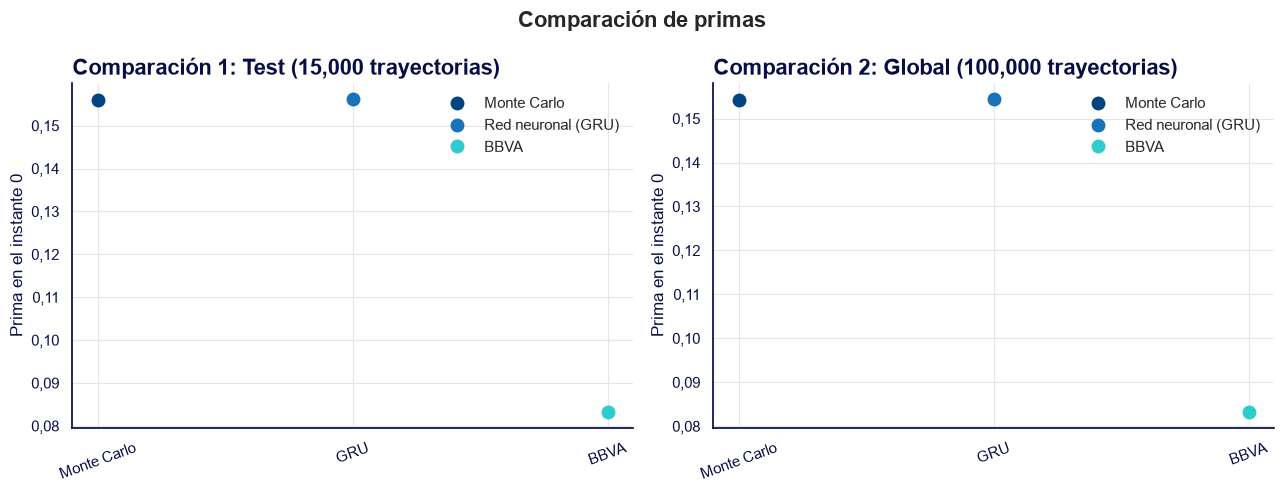

In [113]:
# Eje X: identificamos cada método
x = np.array([0, 1, 2])

# Valores de las primas
primas_test = [
    prima_mc_test,
    prima_red_test,
    prima_bbva_t0
]

primas_global = [
    prima_mc_total,
    prima_red_total,
    prima_bbva_t0
]

# Crear figura con dos columnas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# GRÁFICO 1: TEST (15.000 TRAYECTORIAS)
axes[0].plot(
    x[0], primas_test[0], "o",
    color=BBVA["principal"],
    markersize=9,
    label="Monte Carlo"
)

axes[0].plot(
    x[1], primas_test[1], "o",
    color=BBVA["medio"],
    markersize=9,
    label="Red neuronal (GRU)"
)

axes[0].plot(
    x[2], primas_test[2], "o",
    color=BBVA["agua"],
    markersize=9,
    label="BBVA"
)

axes[0].set_title("Comparación 1: Test (15.000 trayectorias)")
axes[0].set_ylabel("Prima en el instante 0")
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    ["Monte Carlo", "GRU", "BBVA"],
    rotation=20
)
axes[0].legend()

# GRÁFICO 2: GLOBAL (100.000 TRAYECTORIAS)
axes[1].plot(
    x[0], primas_global[0], "o",
    color=BBVA["principal"],
    markersize=9,
    label="Monte Carlo"
)

axes[1].plot(
    x[1], primas_global[1], "o",
    color=BBVA["medio"],
    markersize=9,
    label="Red neuronal (GRU)"
)

axes[1].plot(
    x[2], primas_global[2], "o",
    color=BBVA["agua"],
    markersize=9,
    label="BBVA"
)

axes[1].set_title("Comparación 2: Global (100.000 trayectorias)")
axes[1].set_ylabel("Prima en el instante 0")
axes[1].set_xticks(x)
axes[1].set_xticklabels(
    ["Monte Carlo", "GRU", "BBVA"],
    rotation=20
)
axes[1].legend()


# FORMATO Y GUARDADO BBVA
fig.suptitle(
    "Comparación de primas",
    fontsize=16,
    fontweight="bold"
)

formato_es(fig)

fig.tight_layout()

guardar_mpl(fig, "comparacion_primas_test_global")

plt.show()